# 01_Exploratory data analysis

Explores what is associated with an anime's score and popularity, using the cleaned table from `00_data_cleaning`. Most analysis uses the 6,801-title recommendation catalog (TV, movies and ONAs scored by at least 1,000 users); release trends use the full table.

The last section measures how concentrated attention is across titles, which sets up the popularity-bias question for the recommender in `02_recommender`.

## 1. Load data

In [12]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

fig_dir = '../figures'
os.makedirs(fig_dir, exist_ok=True)

df = pd.read_parquet('../data/processed/anime_clean.parquet')
cat = df[df['in_catalog'] == 1].copy()
cat['log_members'] = np.log10(cat['members'])

print(f'Full table: {len(df):,} titles')
print(f'Catalog:    {len(cat):,} titles')

Full table: 30,763 titles
Catalog:    6,801 titles


## 2. Score and popularity

Score is the average user rating (1 to 10). Members is the number of users who added the title to their list, used here as the popularity measure. Members is plotted on a log scale because of its long right tail.

count    6801.00
mean        7.01
std         0.83
min         2.02
25%         6.54
50%         7.08
75%         7.53
max         9.25
Name: score, dtype: float64


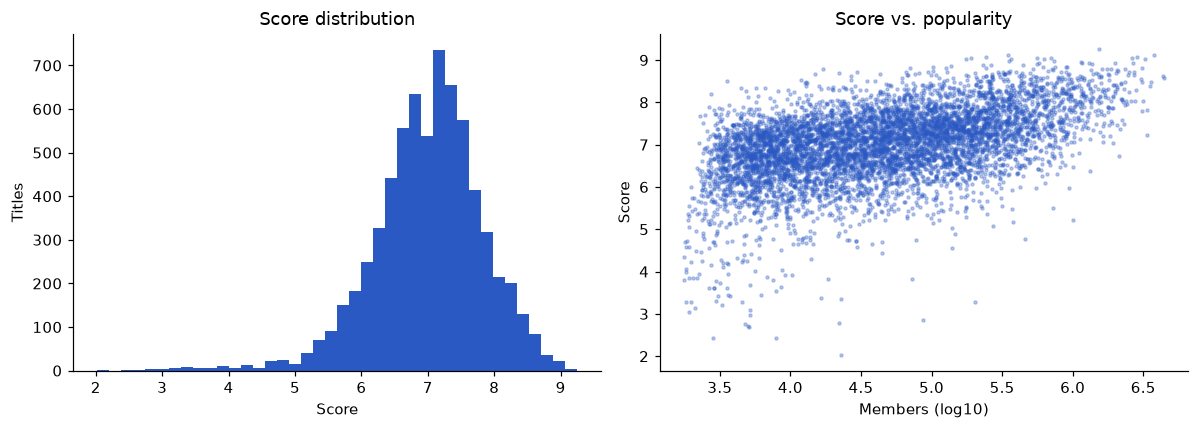

Spearman correlation, score vs. members: 0.48


In [13]:
print(cat['score'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(cat['score'], bins=40, color='#2B59C3')
axes[0].set(title='Score distribution', xlabel='Score', ylabel='Titles')

axes[1].scatter(cat['log_members'], cat['score'], s=4, alpha=0.3, color='#2B59C3')
axes[1].set(title='Score vs. popularity', xlabel='Members (log10)', ylabel='Score')
plt.tight_layout()
plt.savefig(f'{fig_dir}/01_score_vs_members.png', bbox_inches='tight')
plt.show()

print(f"Spearman correlation, score vs. members: {cat['score'].corr(cat['members'], method='spearman'):.2f}")

## 3. Format and source material

Compares titles by format (TV, movie, ONA) and by source material (manga, light novel, original, and so on). Medians are used because both score and members are skewed.

In [14]:
def summarize(data, col, min_n=30):
    out = (data.groupby(col)
               .agg(titles=('anime_id', 'size'),
                    median_score=('score', 'median'),
                    median_members=('members', 'median'))
               .query('titles >= @min_n')
               .sort_values('median_score', ascending=False))
    out['median_members'] = out['median_members'].round(0).astype(int)
    return out.round(2)

summarize(cat, 'type')

,titles,median_score,median_members
type,,,
Movie,1451,7.21,20359
TV,4390,7.07,70336
ONA,960,6.78,11089


In [15]:
by_source = summarize(cat, 'source')
by_source

,titles,median_score,median_members
source,,,
Web novel,132,7.60,9056
Manga,2425,7.27,66389
Novel,245,7.20,30021
Light novel,758,7.12,179800
Web manga,346,7.08,56596
Book,50,7.00,7318
Original,1564,6.89,19097
Unknown,84,6.88,5684
4-koma manga,171,6.85,46133


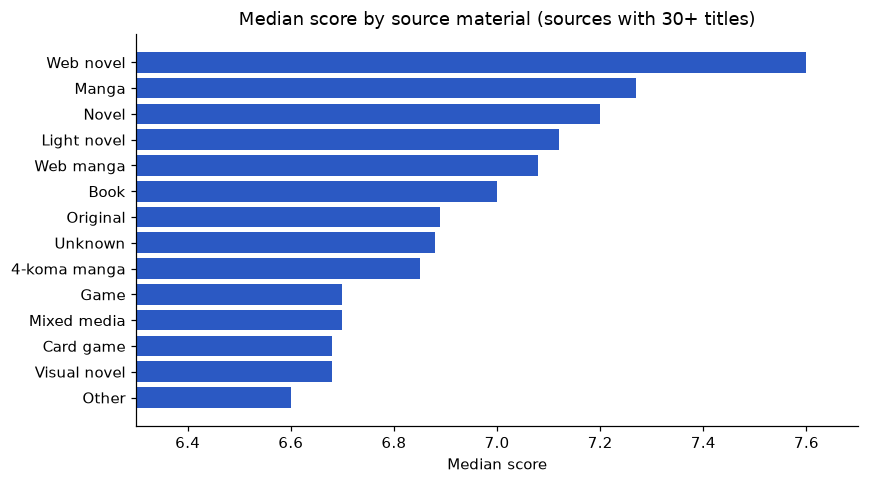

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(by_source.index[::-1], by_source['median_score'][::-1], color='#2B59C3')
ax.set(title='Median score by source material (sources with 30+ titles)', xlabel='Median score')
ax.set_xlim(by_source['median_score'].min() - 0.3, by_source['median_score'].max() + 0.1)
plt.tight_layout()
plt.savefig(f'{fig_dir}/01_score_by_source.png', bbox_inches='tight')
plt.show()

## 4. Genres

Each title can have several genres, so the table is exploded to one row per title-genre pair. A title with three genres therefore counts once in each of those genres.

In [17]:
genre_long = cat[['anime_id', 'score', 'members', 'genres']].explode('genres').dropna(subset=['genres'])
by_genre = summarize(genre_long, 'genres', min_n=50)
by_genre

,titles,median_score,median_members
genres,,,
Award Winning,181,7.77,155478
Iyashikei,102,7.66,92424
Organized Crime,63,7.58,200602
Love Polygon,81,7.52,270284
Gag Humor,142,7.46,86172
...,...,...,...
Harem,289,6.75,193919
Strategy Game,139,6.74,20365
Ecchi,365,6.65,111280


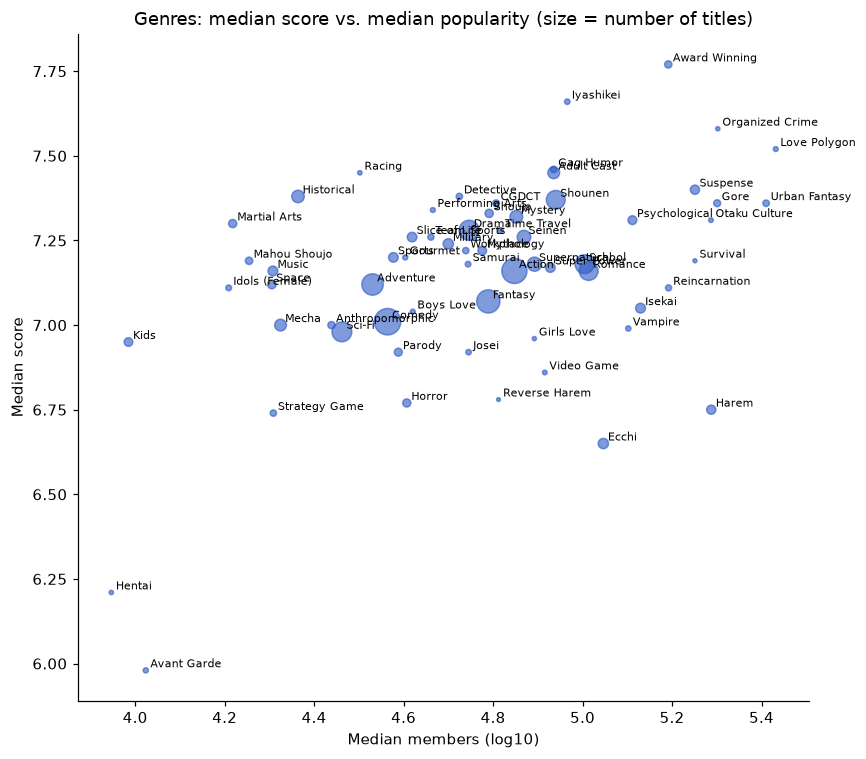

In [18]:
plot = by_genre.sort_values('titles')
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(np.log10(plot['median_members']), plot['median_score'],
                s=plot['titles'] / 8, alpha=0.6, color='#2B59C3')
for g, r in plot.iterrows():
    ax.annotate(g, (np.log10(r['median_members']), r['median_score']), fontsize=7,
                xytext=(3, 2), textcoords='offset points')
ax.set(title='Genres: median score vs. median popularity (size = number of titles)',
       xlabel='Median members (log10)', ylabel='Median score')
plt.tight_layout()
plt.savefig(f'{fig_dir}/01_genre_map.png', bbox_inches='tight')
plt.show()

## 5. Release trends

The number of titles released per year uses the full table. Median score by year uses the catalog only, so older years include only titles that are still rated by at least 1,000 users today. This favors well-remembered classics and should be read with that bias in mind.

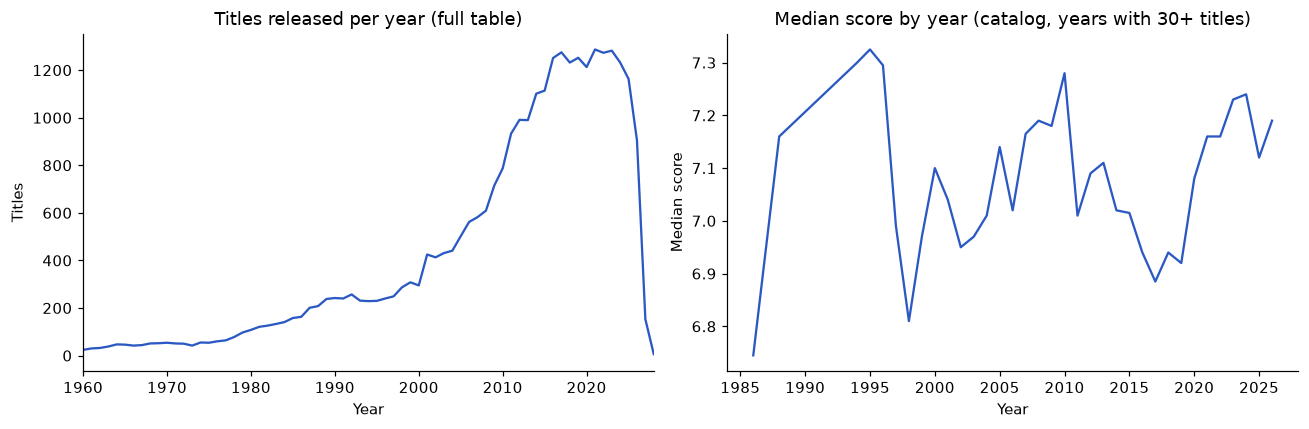

year
2021.0    1287
2022.0    1273
2023.0    1282
2024.0    1232
2025.0    1163
2026.0     905
2027.0     153
2028.0       6
dtype: int64

In [19]:
per_year = df.dropna(subset=['year']).groupby('year').size()
score_year = cat.dropna(subset=['year']).groupby('year')['score'].median()
cat_year = cat.dropna(subset=['year']).groupby('year').size()
score_year = score_year[cat_year >= 30]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(per_year.index, per_year.values, color='#2B59C3')
axes[0].set(title='Titles released per year (full table)', xlabel='Year', ylabel='Titles')
axes[0].set_xlim(1960, per_year.index.max())

axes[1].plot(score_year.index, score_year.values, color='#2B59C3')
axes[1].set(title='Median score by year (catalog, years with 30+ titles)', xlabel='Year', ylabel='Median score')
plt.tight_layout()
plt.savefig(f'{fig_dir}/01_release_trends.png', bbox_inches='tight')
plt.show()

per_year.tail(8)

In [20]:
summarize(cat.dropna(subset=['season']), 'season')

,titles,median_score,median_members
season,,,
Fall,1787,7.12,43301
Spring,1950,7.11,38460
Winter,1434,7.06,44372
Summer,1576,7.02,47250


## 6. Studios

Studio is missing for part of the table, so only titles with a known studio are included. Studios with fewer than 20 catalog titles are excluded to avoid ranking studios on a handful of shows.

In [21]:
studio_long = cat[['anime_id', 'score', 'members', 'studios']].explode('studios').dropna(subset=['studios'])
by_studio = summarize(studio_long, 'studios', min_n=20)
print(f'Studios with 20+ catalog titles: {len(by_studio)}')
by_studio.head(15)

Studios with 20+ catalog titles: 87


,titles,median_score,median_members
studios,,,
Studio Ghibli,26,7.94,301916
Kyoto Animation,70,7.74,189618
CloverWorks,51,7.71,218926
White Fox,34,7.56,338626
MAPPA,73,7.55,152772
ufotable,44,7.54,213506
Wit Studio,56,7.52,98068
A-1 Pictures,145,7.47,208846
Bandai Namco Pictures,43,7.47,26108


## 7. Concentration of attention

Measures how much of total member activity goes to the most popular titles. If a small share of titles holds most of the attention, a recommender trained or evaluated on popularity will keep surfacing the same shows. This is the popularity-bias problem tested in `02_recommender`.

Top   1% of titles (69) hold 15.5% of all members
Top   5% of titles (341) hold 42.3% of all members
Top  10% of titles (681) hold 58.9% of all members
Top  20% of titles (1,361) hold 76.7% of all members


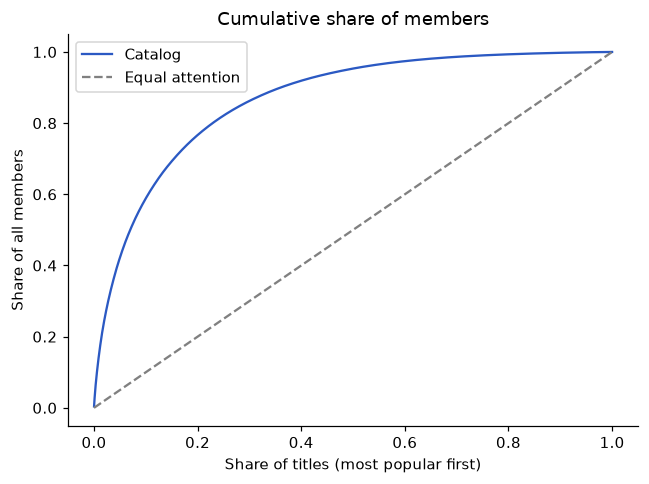

In [22]:
m = cat['members'].sort_values(ascending=False).to_numpy()
cum_share = m.cumsum() / m.sum()
title_share = np.arange(1, len(m) + 1) / len(m)

for p in [0.01, 0.05, 0.10, 0.20]:
    k = int(np.ceil(p * len(m)))
    print(f'Top {p:>4.0%} of titles ({k:,}) hold {cum_share[k - 1]:.1%} of all members')

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(title_share, cum_share, color='#2B59C3', label='Catalog')
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Equal attention')
ax.set(title='Cumulative share of members', xlabel='Share of titles (most popular first)',
       ylabel='Share of all members')
ax.legend()
plt.tight_layout()
plt.savefig(f'{fig_dir}/01_attention_concentration.png', bbox_inches='tight')
plt.show()

## Key findings

- **Score and popularity are moderately related.** The Spearman correlation between score and members is 0.48. Popular titles tend to be rated higher, but popularity alone does not identify quality, so a recommender that leans on popularity will miss well-rated niche titles.
- **Source material separates reach from rating.** Light-novel adaptations have by far the highest median audience (179,800 members) but only a mid-range score (7.12). Manga adaptations combine a large audience (66,389) with a high score (7.27). Web novels score highest (7.60) on a small, low-reach base. Originals (6.89) and game adaptations (6.70) rank below most adapted sources.
- **Format matters more for reach than for rating.** TV series have the largest median audience (70,336 members), more than three times that of movies (20,359) and six times that of ONAs (11,089). Median scores differ by less than half a point (6.78 to 7.21).
- **Genre and studio show clear quality tiers.** *Award Winning*, *Iyashikei* and *Organized Crime* lead median scores among genres with 50+ titles, while *Avant Garde* and *Ecchi* trail. Among studios with 20+ titles, Studio Ghibli (7.94), Kyoto Animation (7.74) and CloverWorks (7.71) lead. These are associations, not causal effects: established studios are also given stronger source material.
- **Release season has almost no effect.** Median scores range only from 7.02 (Summer) to 7.12 (Fall).
- **Attention is highly concentrated.** The top 1% of catalog titles hold 15.5% of all members, the top 10% hold 58.9%, and the top 20% hold 76.7%. A recommender that follows popularity will keep surfacing the same few hundred titles, which is the popularity-bias question tested in `02_recommender`.